<a href="https://colab.research.google.com/github/parul-lakhotia/w281-assignment/blob/main/solutions/assignment5/assignment5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 5: Image Stitching

MIDS W281: Computer Vision

## Recommended Libraries

In [1]:
# Colab setup: install packages and fetch assignment files if needed.
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip -q install opencv-python-headless matplotlib numpy pillow

# Working directory: this notebook's folder (has align_images/ and utils.py)
if IN_COLAB:
    from pathlib import Path
    here = Path.cwd()
    if not (here / "align_images" / "src.png").exists():
        # Private W281 org repo cannot be cloned without a token.
        # Public/personal copy used in this course workflow:
        !git clone --depth 1 https://github.com/parul-lakhotia/w281-assignment.git /content/w281-assignment
        %cd /content/w281-assignment/solutions/assignment5

print("cwd:", os.getcwd())
print("src exists:", os.path.exists("align_images/src.png"))


Cloning into '/content/w281-assignment'...
remote: Enumerating objects: 108, done.
remote: Counting objects: 100% (108/108), done.
remote: Compressing objects: 100% (103/103), done.
remote: Total 108 (delta 4), reused 98 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (108/108), 99.61 MiB | 28.25 MiB/s, done.
Resolving deltas: 100% (4/4), done.
/content/w281-assignment/solutions/assignment5
cwd: /content/w281-assignment/solutions/assignment5
src exists: True


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
from utils import warp_image_with_bounds

def as_uint8_rgb(img):
    img = np.asarray(img)
    if img.ndim == 3 and img.shape[2] == 4:
        img = img[..., :3]
    if np.issubdtype(img.dtype, np.floating):
        img = (np.clip(img, 0, 1) * 255).astype(np.uint8)
    return img


def image_corners(img):
    h, w = img.shape[:2]
    return np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)


def bounds_from_corners(pts):
    pts = pts.reshape(-1, 2)
    xmin = int(np.floor(pts[:, 0].min()))
    ymin = int(np.floor(pts[:, 1].min()))
    xmax = int(np.ceil(pts[:, 0].max()))
    ymax = int(np.ceil(pts[:, 1].max()))
    return [xmin, ymin, xmax, ymax]


![Hybrid Teaser](https://raw.githubusercontent.com/W281/fileRepository/main/Assignments/Assignment_5/teaser.png)

 ### Overview
Remember in class you learned how to compute the homography between two planar surfaces. In this assignment, you will use that knowledge to stitch together the images of the above restaurant advertisement.

 ### Description
 There are two images inside the ***align_images*** directory. You will write Python code to perform the following.

 1. **Homography Computation:** Write a Python function that takes as input two images (source and destination image) and computes the homography from the source to the destination image. You can use the `findHomography` method in OpenCV. The homography calculation requires at least four point correspondences between the two images, which you can select manually. However, with only four points the homography recovery can be prone to noise, so feel free to select more than four point correspondences.
Establishing point correspondences is very important because an error of just a few pixels can produce large errors in the recovered homography. We have provided a set of four hard-coded point correspondences in the code, but you should also try to add more points and compute the homography with your own set of points. You can provide point matches with a mouse-clicking interface such as `ginput`. Display a plot showing the point-correspondences on the two images and print the computed homography.  

2. **Image Bounds:** As the final output image should be large enough to contain both the transformed source image and the destination image, we need to first compute the size of the final image. For this, you will use the corners of the source and destination images i.e `(0, 0, im.shape[1], im.shape[0])` to find the bounds for the final image. Warp the the source corners using the above homography, and combine with the destination corners to compute the final bounds. You can use the `perspectiveTransform` method from Python's OpenCV library to warp the source bounds.    
    ***Hint: The final image bounds can have negative values, which means that the source image, after warping, will lie above and/or left of the (0,0) position in the destination image.***

3. **Image Warping:** In order to stitch the `src` and `dest` images, you need to warp the `src` to the `dest` image first. You will do this warping using the `warp_image_with_bounds` provided to you in utils.py. The function expects the source image, homography, and the final image bounds computed above. The output of the function will be large enough to contain both source and destination images. However, the output image will contain only the source image warped to the destination space and translated so that the left-top of the output image is at (0,0) (remember the negative values in the image bounds).  

4. **Image-pair stitching:** Finally place the destination image into the final output. The output image has been translated so that the left-top of the output image is at (0,0). You will need to shift the destination image by the same amount before placing it in the output image. You can simply replace the pixel values of the output image with destination image (we are not doing any blending at the image seam).  

5. **Image rectification:** Finally, you will rectify the stitched image so that the windows become frontal-parallel. This is the same as was done in the class exercise, where you can assume that each of the two large windows is square. For this part, use the four corners of the window in the stitched image (see above figure) and transform it to the destination points given in the code. Select the points in the correct order. Finally, display and submit the rectified image. You can use the image warping code from above.  

### Deliverables:

- A plot displaying the selected point correspondences between the images
- The computed homography between the images (print the matrix)
- The output image after stitching
- The output image after rectification
- Python code for homography compuation, image stitching, and image rectification

For full credit, please ensure your bounds match at least one of the examples at the top or bottom.

In [3]:
def find_homography_manual(img_src_path, img_dst_path):
    img_src = as_uint8_rgb(plt.imread(img_src_path))
    img_dst = as_uint8_rgb(plt.imread(img_dst_path))

    # Provided correspondences (src -> dest). Extra points can be added here.
    pts_src = np.array([
        [1649.15, 298],
        [2293.79, 236.60],
        [2243.19, 2168.90],
        [1770.98, 2133.52],
    ], dtype=np.float32)

    pts_dst = np.array([
        [495, 100],
        [1135, 131],
        [1021, 1986],
        [555, 1995],
    ], dtype=np.float32)

    fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 10))
    ax[0].imshow(img_src)
    ax[0].axis("off")
    ax[0].plot(pts_src[:, 0], pts_src[:, 1], "r*", markersize=10)
    ax[0].set_title("Source correspondences")
    ax[1].imshow(img_dst)
    ax[1].axis("off")
    ax[1].plot(pts_dst[:, 0], pts_dst[:, 1], "r*", markersize=10)
    ax[1].set_title("Destination correspondences")
    plt.show()

    H, mask = cv2.findHomography(pts_src, pts_dst, method=0)
    print("Homography (source -> destination):")
    print(H)
    return H


def stitch_images(img_src_path, img_dst_path):
    H = find_homography_manual(img_src_path, img_dst_path)

    img_src = as_uint8_rgb(plt.imread(img_src_path))
    img_dst = as_uint8_rgb(plt.imread(img_dst_path))

    src_warped = cv2.perspectiveTransform(image_corners(img_src), H)
    all_corners = np.concatenate([src_warped, image_corners(img_dst)], axis=0)
    xmin, ymin, xmax, ymax = bounds_from_corners(all_corners)
    print("Stitched image bounds [xmin, ymin, xmax, ymax] =", [xmin, ymin, xmax, ymax])

    result = warp_image_with_bounds(img_src, H, [xmin, ymin, xmax, ymax])

    # Destination is translated by the same shift used in warp_image_with_bounds.
    tx, ty = -xmin, -ymin
    h_d, w_d = img_dst.shape[:2]
    result[ty : ty + h_d, tx : tx + w_d] = img_dst

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(20, 10))
    ax.imshow(result)
    ax.axis("off")
    ax.set_title("Stitched image")
    plt.show()
    return result


def rectify(img_src_path):
    # Four corners of a large window in the stitched image (order matches pts_dst).
    pts_src = np.array(
        [
            [464.48358, 727.9149],
            [2370.2458, 796.1351],
            [2310.8284, 2484.0332],
            [277.4284, 2525.8455],
        ],
        dtype=np.float32,
    )
    pts_dst = np.array(
        [[0, 0], [2000, 0], [2000, 2000], [0, 2000]],
        dtype=np.float32,
    )
    img_src = as_uint8_rgb(plt.imread(img_src_path))

    H, mask = cv2.findHomography(pts_src, pts_dst, method=0)
    print("Rectification homography:")
    print(H)

    warped = cv2.perspectiveTransform(image_corners(img_src), H)
    xmin, ymin, xmax, ymax = bounds_from_corners(warped)
    print("Rectified image bounds [xmin, ymin, xmax, ymax] =", [xmin, ymin, xmax, ymax])

    result = warp_image_with_bounds(img_src, H, [xmin, ymin, xmax, ymax])

    fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(20, 10))
    ax.imshow(result)
    ax.axis("off")
    ax.set_title("Rectified image")
    plt.show()
    return result


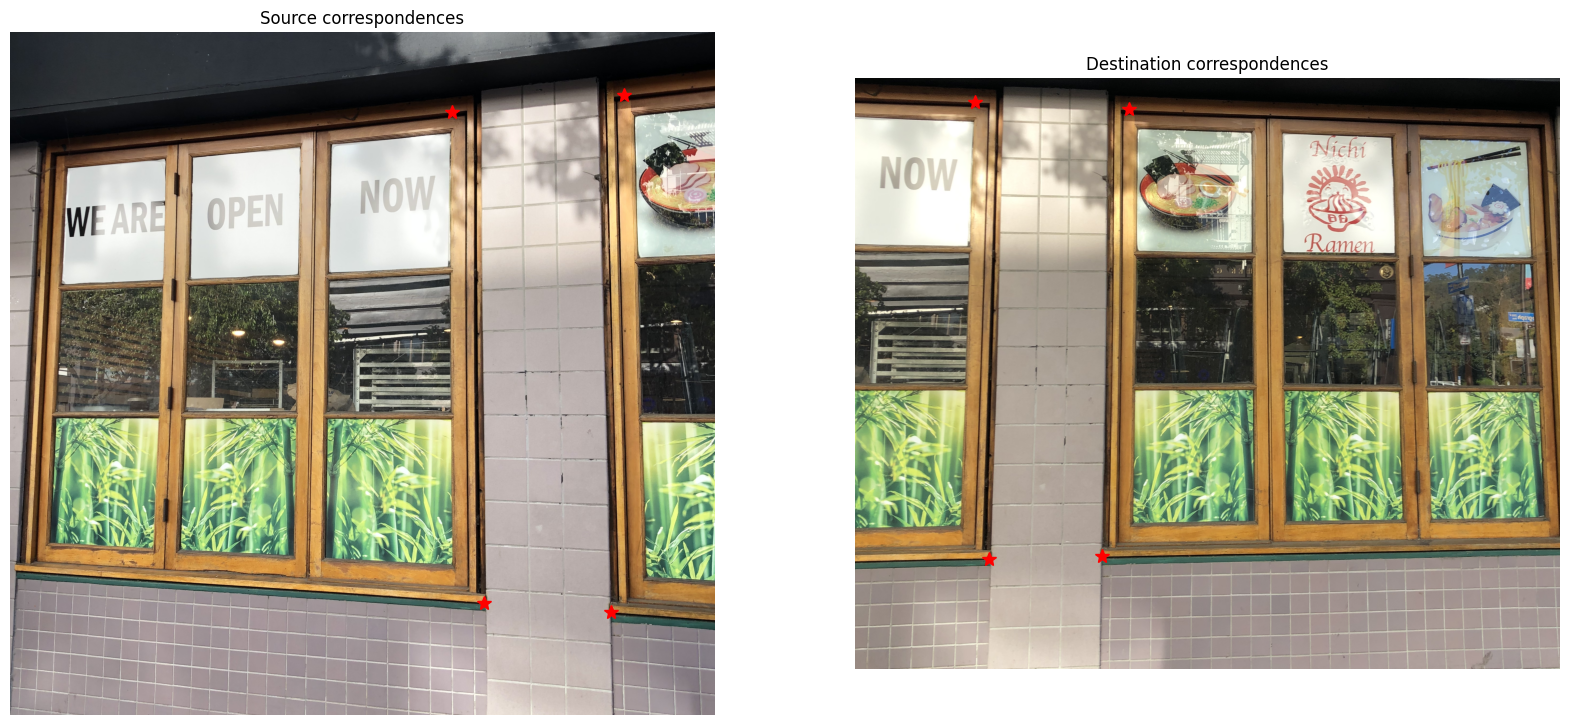

Homography (source -> destination):
[[ 1.45374952e+00 -4.90632713e-02 -1.75080588e+03]
 [ 2.09598977e-01  1.32473444e+00 -6.12749340e+02]
 [ 1.68016703e-04 -8.99113847e-07  1.00000000e+00]]
Stitched image bounds [xmin, ymin, xmax, ymax] = [-1881, -613, 2923, 2776]


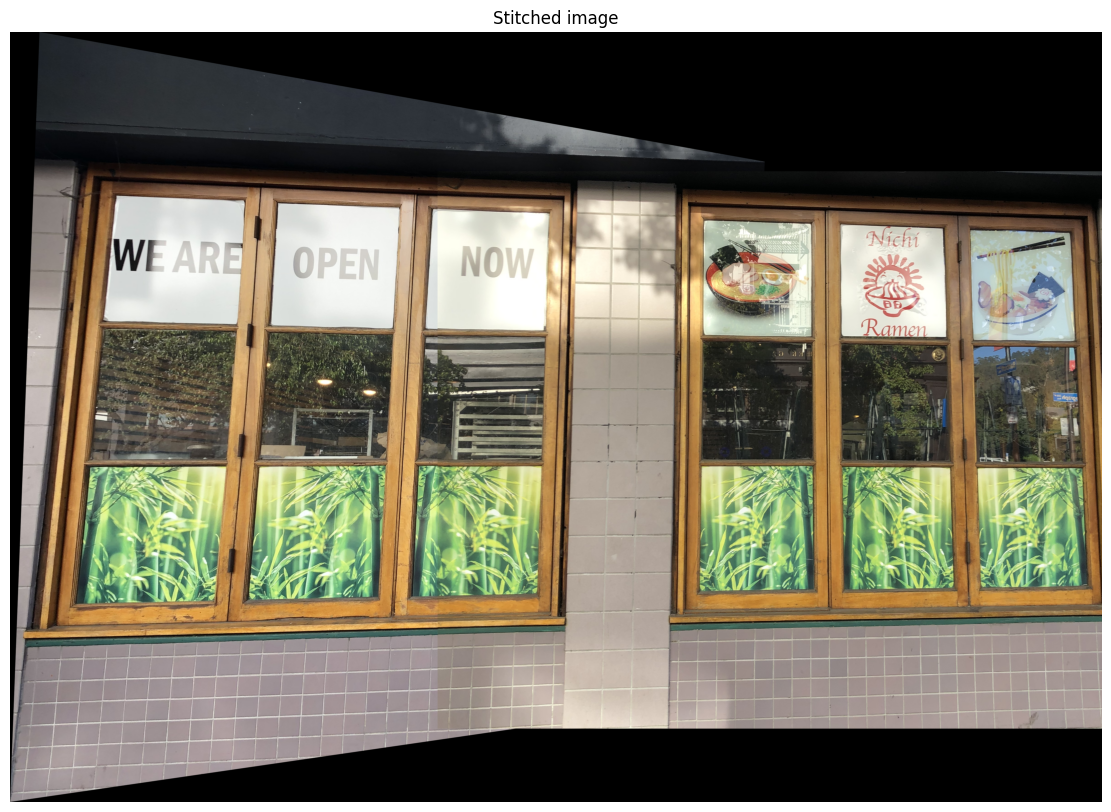

saved deliverable/stitched.png
Rectification homography:
[[ 9.91543797e-01  1.03159380e-01 -5.35647066e+02]
 [-4.26143078e-02  1.19045085e+00 -8.46753283e+02]
 [-3.28686513e-05  3.29704569e-05  1.00000000e+00]]
Rectified image bounds [xmin, ymin, xmax, ymax] = [-536, -1249, 5021, 3128]


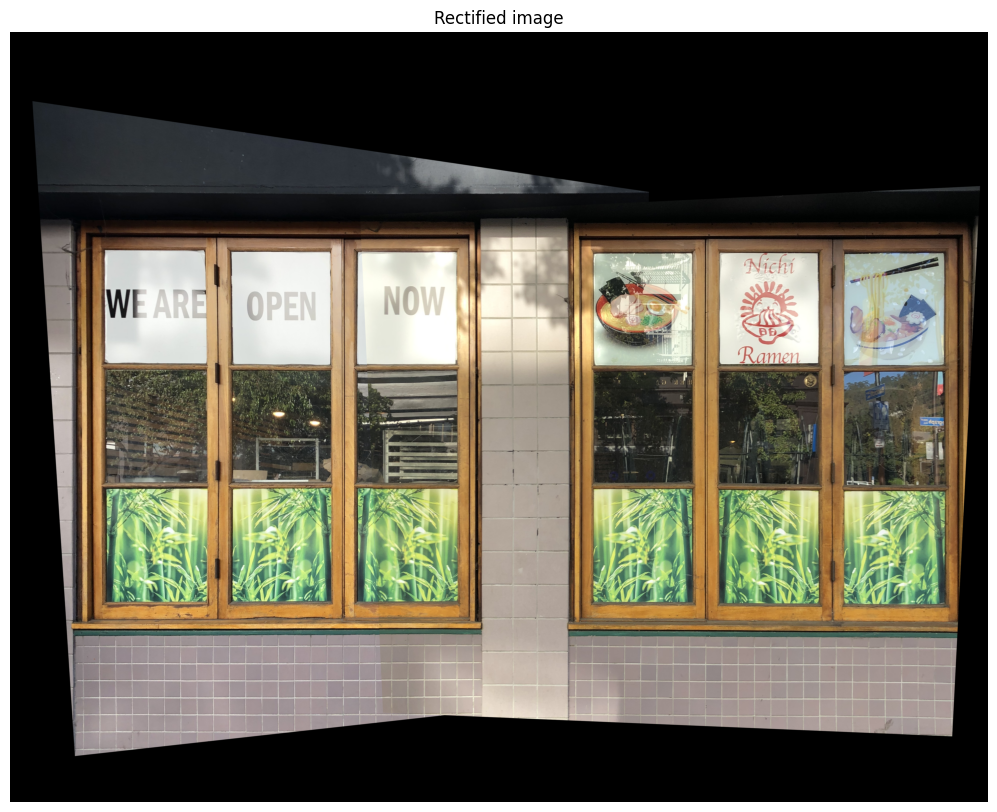

saved deliverable/rectified.png


In [4]:
img_src_path = "align_images/src.png"
img_dst_path = "align_images/dest.png"
os.makedirs("deliverable", exist_ok=True)
stitched_path = "deliverable/stitched.png"
rectified_path = "deliverable/rectified.png"

out = stitch_images(img_src_path, img_dst_path)
plt.imsave(stitched_path, out)
print("saved", stitched_path)

rect = rectify(stitched_path)
plt.imsave(rectified_path, rect)
print("saved", rectified_path)
